# 07 - Spatial re-ranking

In the previous notebook, we looked at found-but-lost errors in Vision Transformers, where patches predict the object class but the CLS token picks another class. Three things stood out:

- The object class is usually the runner-up. For almost all found-but-lost composites, it is in the top 5, with a median rank of 2.
- Up to block 10, the CLS token moves towards the object together with the patches. Only in the last block does it turn away.
- In blocks 9 and 10, the runner-up is usually the more compact class on the patch grid, while the wrongly predicted class is more spread out.

So the right answer is still there, and these errors seem to follow a pattern that we might be able to use. In this notebook, we try to recover some of them by using these signals to decide when to swap the final prediction for the runner-up.

Please keep in mind that we see this as a probe. We choose the rules on the same 75,000 composites we evaluate them on, so the gains show what these signals can recover on this subset. How well they work on new images would still need to be tested.

In [2]:
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"
CONSENSUS_PATH = DATA_DIR / "semantic_axes" / "consensus.npy"

# Logit-lens results written by notebook 06
LOGIT_LENS_DIR = OUTPUT_DIR / "logit_lens"

# ImageNet-OOC1k dataset: we only need the mechanism subset from notebook 02
DATASET_DIR = REPO_ROOT / "ImageNet-OOC1k"
SUBSET_PATH = DATASET_DIR / "generated" / "mechanism_subset.csv"

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Analysis and plotting functions live outside the notebook to keep it readable.
from ooc1k.analysis.patch_competition import (
    get_compactness,
    get_outcomes,
    get_rerank_accuracy,
    get_rerank_signals,
    get_true_class_rank,
    load_logit_lens_results,
    load_subset,
)
from ooc1k.plotting.e_patch_competition import MODEL_LABELS
from ooc1k.plotting.f_reranking import (
    plot_recovery_breakage,
    plot_rerank_accuracy,
    plot_rerank_overview,
    plot_rerank_signals,
)

## Settings

We use the same five ViTs as in notebook 06. `MODEL` selects the ViT for the first sections; the last section applies the rule to all five. As before, ViT-RelPos-B/16 has no CLS token, so its "CLS prediction" comes from the averaged patch tokens.

`TAU`, `MIN_OBJECT_PATCHES` and `CLEAN_BALANCE` define the outcome types exactly as in notebook 06. `GATE_BLOCK` is the block in which we measure compactness, and `RULE` is the re-ranking rule we use in the paper. Both are explained below.

In [4]:
MODELS = ["ViT-B-16", "ViT-S-16", "ViT-L-16", "DeiT-B-16", "ViT-RelPos-B-16"]
MODEL = "ViT-B-16"          # try any of the models above

TAU = 0.0945                # semantic pull below which a patch is undecided
MIN_OBJECT_PATCHES = 20     # exact object patches needed to count as detected
CLEAN_BALANCE = 0.75        # realm balance above which a correct composite is a clean win

GATE_BLOCK = -2             # block of the compactness signal: the penultimate one (10 for ViT-B/16, 22 for ViT-L/16)
RULE = {"a_min": 1.0, "g_max": 1.0, "d_min": 0.5}  # swap if a > a_min, g < g_max and d > d_min
BIN_WIDTH = 40              # ranks per bin in the accuracy curves (25 bins along the axis)

## Loading the results from notebook 06

We load the logit-lens results of all five models and sort every composite into its outcome type again.

In [5]:
subset = load_subset(SUBSET_PATH, CLASS_INDEX)
consensus = np.load(CONSENSUS_PATH)

results = {model: load_logit_lens_results(LOGIT_LENS_DIR / f"{model}_logit_lens.h5", subset) for model in MODELS}
outcomes = {
    model: get_outcomes(results[model], subset, consensus, TAU, min_object_patches=MIN_OBJECT_PATCHES, clean_balance=CLEAN_BALANCE)
    for model in MODELS
}
print(f"{MODEL}: {(outcomes[MODEL] == 'Found-but-lost').sum():,} found-but-lost composites out of {len(subset):,}")

ViT-B-16: 10,545 found-but-lost composites out of 75,000


## Three signals of a near miss

We now turn these observations into three signals. For each composite, we compare the two classes with the highest final CLS logits: the predicted class $\hat{c}_1$ and the runner-up $\hat{c}_2$.

**Logit gap.** First, we look at how far apart the two candidates are in score:

$$
g = z_{\hat{c}_1} - z_{\hat{c}_2}
$$

Here, $z_c$ is the final CLS logit for class $c$. A small gap means the model only slightly prefers its prediction over the runner-up, so swapping them would require only a small change in their scores.

**Compactness advantage.** Next, we look at where the patches predicting each class are on the grid at `GATE_BLOCK`. As in notebook 06, we measure their spread as the mean distance from their centre:

$$
\operatorname{spread}(c)
=
\frac{1}{|P_c|}
\sum_{\mathbf p \in P_c}
\left\|\mathbf p-\bar{\mathbf p}_c\right\|_2
$$

$P_c$ contains the positions of patches predicting class $c$ on the 14×14 grid, and $\bar{\mathbf p}_c$ is their mean position. Smaller spread means these patches sit closer together. If no patch predicts a class, we assign it the largest possible spread.

We then compare the two classes:

$$
a = \operatorname{spread}(\hat{c}_1)
  - \operatorname{spread}(\hat{c}_2)
$$

A positive value means the runner-up forms the more compact group. This is the pattern we often saw in found-but-lost cases: the object predictions stay together, while the wrongly predicted class is more spread out.

**Semantic distance.** Finally, we check how related the two candidates are using the consensus matrix from notebook 01:

$$
d = D(\hat{c}_1,\hat{c}_2)
$$

If the candidates are close neighbours, such as two dog breeds, the model may simply be unsure between similar classes. A larger distance is more consistent with the competition between object and background that we want to examine.

The histograms below compare these signals for found-but-lost composites, which we want to recover, and correctly classified composites, where a swap would introduce an error. The shaded regions show the values that satisfy each condition in `RULE`.

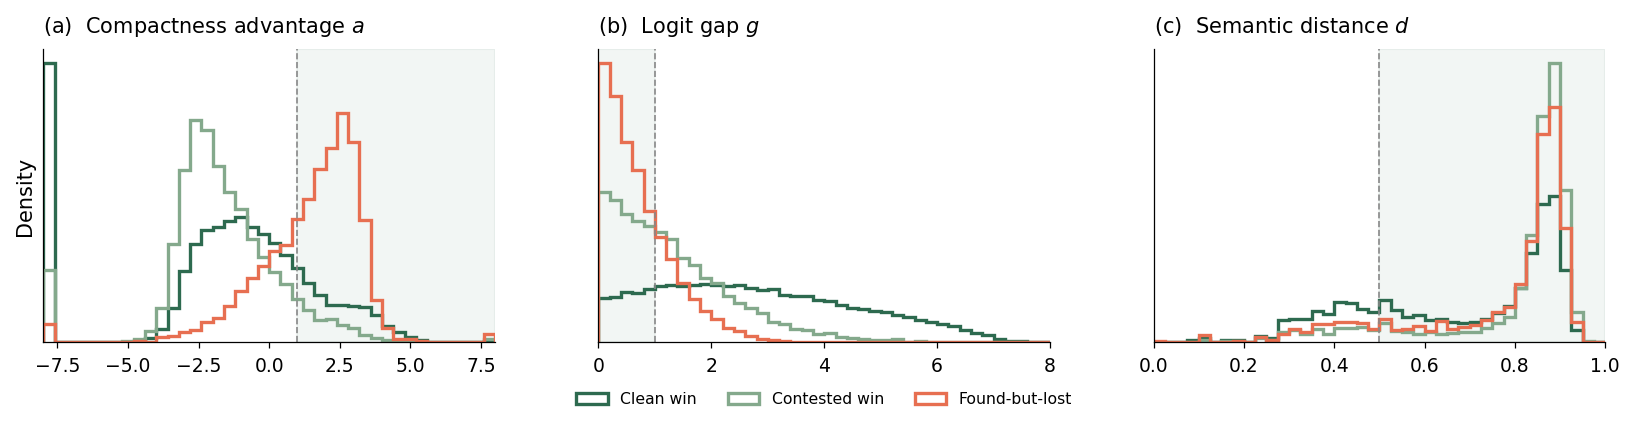

,gap,advantage,distance
outcome,,,
Clean win,2.63,-1.08,0.76
Contested win,1.09,-1.87,0.87
Found-but-lost,0.58,1.86,0.85
No detection,1.05,0.62,0.77


In [6]:
signals = get_rerank_signals(results[MODEL], consensus, GATE_BLOCK)

fig = plot_rerank_signals(signals, outcomes[MODEL], RULE)
fig.savefig(FIG_DIR / "rerank_signals.pdf")
plt.show()

# Median of every signal, per outcome type
signals[["gap", "advantage", "distance"]].groupby(outcomes[MODEL], observed=False).median().round(2)

## The re-ranking rule

Here, $a$ is the **compactness advantage**: positive values mean the runner-up’s patches are more tightly grouped than those of the predicted class. We swap the prediction for the runner-up when this advantage is large enough and the logit gap $g$ is small enough:

$$
\text{swap if} \quad a > a_{\min} \quad \text{and} \quad g < g_{\max}.
$$

If we also use the semantic distance filter, the two classes must be sufficiently far apart: $d > d_{\min}$.

The rule only takes a few lines, so we define it here. `evaluate_rerank` then counts how many found-but-lost errors we recover, how many other errors become correct, and how many correct predictions become wrong.

In [7]:
def rerank(signals, a_min, g_max, d_min=None):
    """Prediction after swapping the top-1 class for the runner-up wherever all conditions hold."""
    swap = (signals["advantage"] > a_min) & (signals["gap"] < g_max)
    if d_min is not None:
        swap &= signals["distance"] > d_min
    return signals["top2"].where(swap, signals["top1"])


def evaluate_rerank(prediction, subset, outcomes):
    """Recovered found-but-lost errors, other corrected errors and broken correct predictions of a re-ranking."""
    correct_before = outcomes.isin(["Clean win", "Contested win"])
    correct_after = prediction == subset["object_class_idx"]
    found_but_lost = outcomes == "Found-but-lost"
    recovered = (found_but_lost & correct_after).sum()
    broken = (correct_before & ~correct_after).sum()
    return {
        "FBL recovered": recovered,
        "Other corrected": (~correct_before & ~found_but_lost & correct_after).sum(),
        "Broken": broken,
        "Ratio": recovered / broken,
        "Net change (pp)": 100 * (correct_after.mean() - correct_before.mean()),
    }


def get_rule_name(rule):
    """Short name of a rule, e.g. "a > 1.0, g < 1.0, d > 0.5"."""
    name = f"a > {rule['a_min']}, g < {rule['g_max']}"
    return name + (f", d > {rule['d_min']}" if "d_min" in rule else "")

Let's apply `RULE` to `MODEL`.

In [8]:
prediction = rerank(signals, **RULE)
result = evaluate_rerank(prediction, subset, outcomes[MODEL])

accuracy = results[MODEL]["composites"]["correct"].mean()
print(f"{get_rule_name(RULE)}: {result['FBL recovered']:,} found-but-lost recovered, {result['Other corrected']:,} other errors corrected, "
      f"{result['Broken']:,} correct predictions broken (ratio {result['Ratio']:.1f}:1)")
print(f"Accuracy: {accuracy:.1%} -> {accuracy + result['Net change (pp)'] / 100:.1%}")

a > 1.0, g < 1.0, d > 0.5: 4,277 found-but-lost recovered, 428 other errors corrected, 456 correct predictions broken (ratio 9.4:1)
Accuracy: 57.2% -> 62.9%


## Recovery versus breakage

How strict should the rule be? Looser thresholds swap more often, so they can recover more found-but-lost errors but also turn more correct predictions into errors.

A close call can also happen between similar classes, such as two dog breeds. To focus on cases that look more like object–background competition, we also test a minimum **semantic distance between the final prediction and the runner-up**, measured on our consensus axis. This means we only swap when the two candidates are sufficiently unrelated.

We compare six rules: three use only the logit gap and compactness advantage, and three also include this distance condition (right group). Above each pair of bars we show the net change in accuracy and the ratio of recovered to broken predictions; the star marks `RULE`.

Without the distance condition, loosening the thresholds quickly breaks more correct predictions. With the same gap and compactness thresholds, adding it roughly halves the number of broken predictions while keeping almost all recoveries. Try adding your own thresholds to `RULES`.

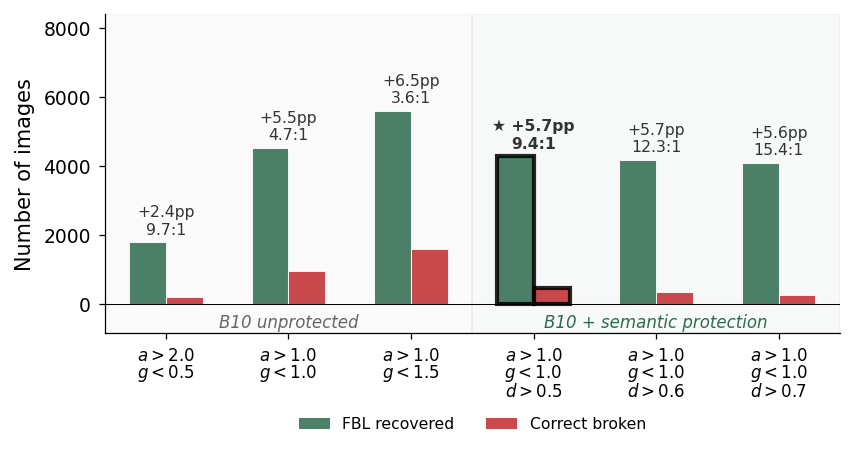

,FBL recovered,Other corrected,Broken,Ratio,Net change (pp)
"a > 2.0, g < 0.5",1786,171,185,9.7,2.4
"a > 1.0, g < 1.0",4523,518,953,4.7,5.5
"a > 1.0, g < 1.5",5601,833,1574,3.6,6.5
"a > 1.0, g < 1.0, d > 0.5",4277,428,456,9.4,5.7
"a > 1.0, g < 1.0, d > 0.6",4184,397,341,12.3,5.7
"a > 1.0, g < 1.0, d > 0.7",4089,363,265,15.4,5.6


In [9]:
RULES = [
    {"a_min": 2.0, "g_max": 0.5},
    {"a_min": 1.0, "g_max": 1.0},
    {"a_min": 1.0, "g_max": 1.5},
    {"a_min": 1.0, "g_max": 1.0, "d_min": 0.5},
    {"a_min": 1.0, "g_max": 1.0, "d_min": 0.6},
    {"a_min": 1.0, "g_max": 1.0, "d_min": 0.7},
]

rules = pd.DataFrame([evaluate_rerank(rerank(signals, **rule), subset, outcomes[MODEL]) for rule in RULES], index=[get_rule_name(rule) for rule in RULES])

gate_block = results[MODEL]["composites"]["patch_predictions"].shape[1] + GATE_BLOCK   # 10 for ViT-B/16
fig = plot_recovery_breakage(rules, selected=get_rule_name(RULE), gate_block=gate_block)
fig.savefig(FIG_DIR / "rerank_rules.pdf")
plt.show()

rules.round(1)

## Accuracy along the semantic axis after re-ranking

Does re-ranking help everywhere on the semantic axis, or only for some distances? We compute the accuracy in bins of `BIN_WIDTH` ranks, before and after re-ranking with `RULE`.

Accuracy goes up across the whole range. The decline with semantic distance stays, though: re-ranking recovers some of the errors, but the background still pulls the prediction away from the object.

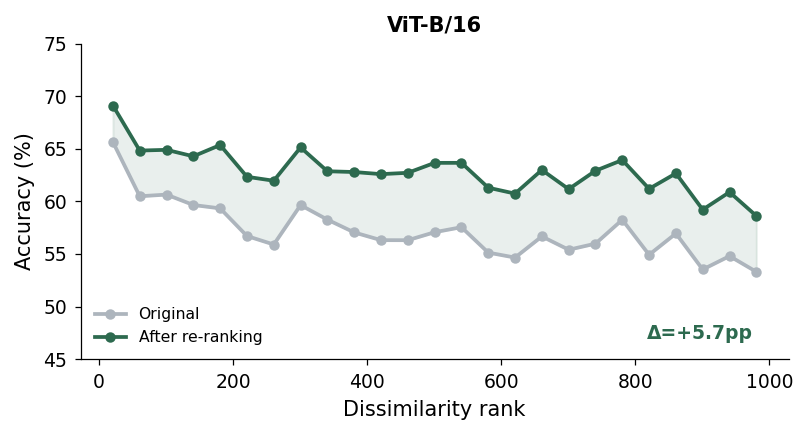

In [10]:
correct_after = prediction == subset["object_class_idx"]
curves = get_rerank_accuracy(results[MODEL]["composites"]["correct"], correct_after, subset, bin_width=BIN_WIDTH)

fig = plot_rerank_accuracy({MODEL: curves})
fig.savefig(FIG_DIR / "rerank_accuracy.pdf")
plt.show()

## The same rule for other ViTs

Is this specific to ViT-B/16? We apply the exact same rule to all five Vision Transformers, without tuning the thresholds for each model.

Re-ranking improves accuracy for all five, although the gains are much smaller for the other models. So these signals also seem useful beyond ViT-B/16, but different models may need different thresholds or rules to recover more of these errors.

In [11]:
reranked, summary = {}, {}
for model in MODELS:
    reranked[model] = rerank(get_rerank_signals(results[model], consensus, GATE_BLOCK), **RULE)
    result = evaluate_rerank(reranked[model], subset, outcomes[model])
    found_but_lost = outcomes[model] == "Found-but-lost"
    ranks = get_true_class_rank(results[model], subset)
    compactness = get_compactness(results[model], outcomes[model], [GATE_BLOCK]).iloc[0]
    summary[MODEL_LABELS[model]] = {
        "Accuracy (%)": 100 * results[model]["composites"]["correct"].mean(),
        "FBL (%)": 100 * found_but_lost.mean(),
        "FBL in top 5 (%)": 100 * (ranks[found_but_lost] <= 5).mean(),
        "Compactness gap (pp)": 100 * (compactness["Found-but-lost"] - compactness["Clean win"]),
        "Net change (pp)": result["Net change (pp)"],
        "Ratio": result["Ratio"],
        "FBL recovered (%)": 100 * result["FBL recovered"] / found_but_lost.sum(),
    }

pd.DataFrame(summary).T.round(1)

,Accuracy (%),FBL (%),FBL in top 5 (%),Compactness gap (pp),Net change (pp),Ratio,FBL recovered (%)
ViT-B/16,57.2,14.1,98.7,49.4,5.7,9.4,40.6
ViT-S/16,46.3,5.7,94.7,17.2,0.9,0.7,13.8
ViT-L/16,58.7,8.2,96.2,19.7,1.1,2.3,16.4
DeiT-B/16,52.5,8.3,96.9,22.2,1.9,2.2,23.9
ViT-RelPos-B/16,51.9,14.9,95.1,23.3,1.9,1.9,22.2


And here we can see the accuracy of all models before and after re-ranking.

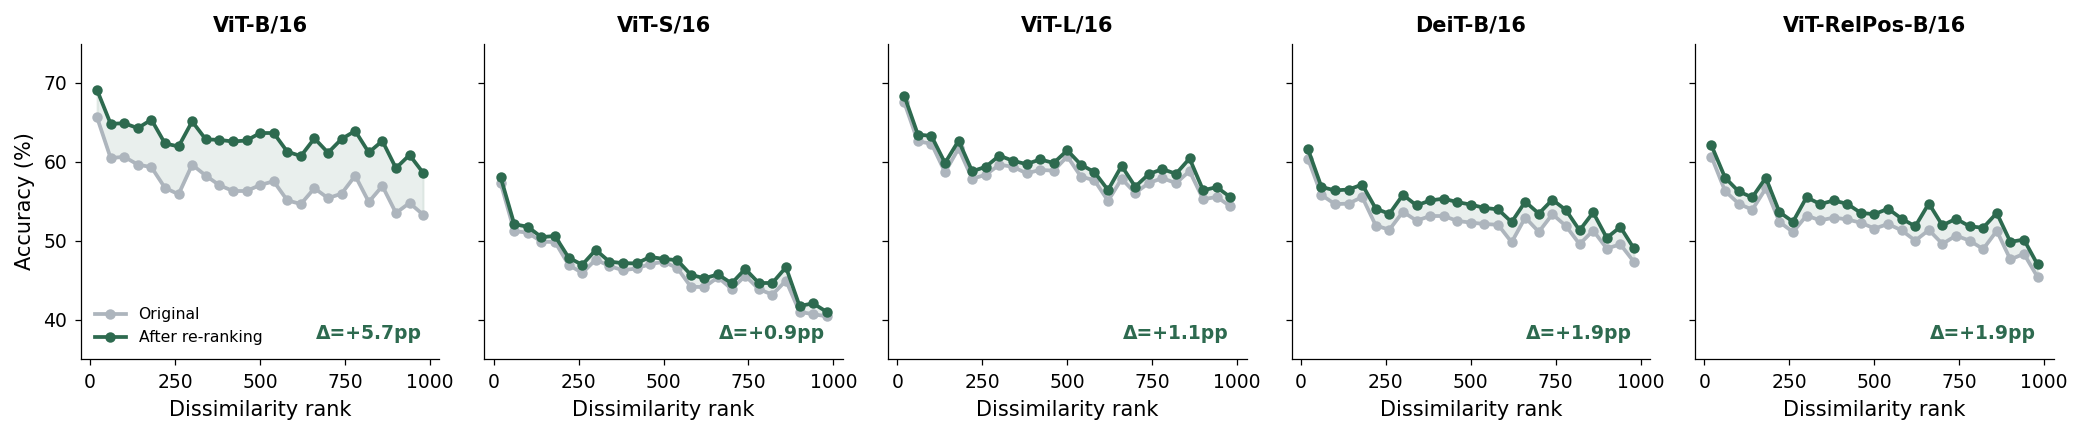

In [12]:
curves = {
    model: get_rerank_accuracy(results[model]["composites"]["correct"], reranked[model] == subset["object_class_idx"], subset, bin_width=BIN_WIDTH)
    for model in MODELS
}

fig = plot_rerank_accuracy(curves)
fig.savefig(FIG_DIR / "rerank_accuracy_all_models.pdf")
plt.show()

## Putting it together

The figure for the paper combines the two main results for `MODEL`: (a) how many found-but-lost errors each rule recovers and how many correct predictions it breaks, and (b) the accuracy before and after re-ranking with `RULE` along the semantic axis.

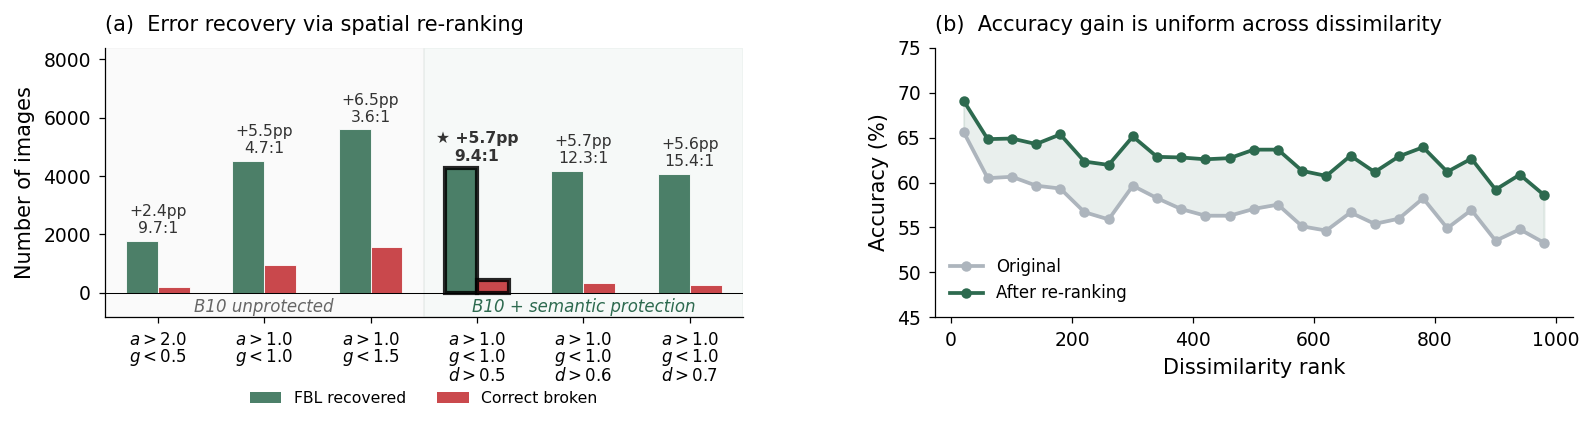

In [13]:
fig = plot_rerank_overview(rules, get_rule_name(RULE), gate_block, curves[MODEL])
fig.savefig(FIG_DIR / "rerank_overview.pdf")
plt.show()